# INT3095 Assignment 2: Abdullah Shahid, 11694038

Imports

In [13]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

Useful method(s)

In [14]:
def new_line():
  print()

#Task 1

In [25]:
diabetes_data=pd.read_csv("/content/diabetes.csv")

print(diabetes_data.describe())

are_diabetic=diabetes_data[diabetes_data["Outcome"]==1]
not_diabetic=diabetes_data[diabetes_data["Outcome"]==0]
new_line()
print(len(are_diabetic),"patients are Diabetic")
print(len(not_diabetic),"are not Diabetic")

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

#Task 2

In [26]:
print("The number of cells in each column whose value is 0")
print((diabetes_data==0).sum())

new_line()
to_replace_columns=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
diabetes_data[to_replace_columns]=diabetes_data[to_replace_columns].replace(0,np.nan)
print("The number of cells per column with a Null in them (step one of data cleaning)")
print(diabetes_data.isnull().sum())


medians=diabetes_data[to_replace_columns].median()
diabetes_data[to_replace_columns]=diabetes_data[to_replace_columns].fillna(medians)
new_line()
print("The number of cells per column with 0 in them (data cleaning finished)")
print(diabetes_data.describe())

The number of cells in each column whose value is 0
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

The number of cells per column with a Null in them (step one of data cleaning)
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

The number of cells per column with 0 in them (data cleaning finished)
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  121.656250      72.386

Use median because it is unaffected by outlier or boundary values as compared with using mean

#Task 3

In [27]:
unscaled_accuracies={}

X=diabetes_data[["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age"]]
Y=diabetes_data["Outcome"]

X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42,shuffle=True,stratify=Y)

new_line()
print(f"Length of X_train is {len(X_train)}")
print(f"Length of X_test is {len(X_test)}")
print(f"Length of Y_train is {len(Y_train)}")
print(f"Length of Y_test is {len(Y_test)}")

new_line()
print("Training KNN model")
knn_model=KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train,Y_train)
predictions=knn_model.predict(X_test)
accuracy=accuracy_score(Y_test,predictions)
unscaled_accuracies["KNN Model"]=accuracy

print("Training Decision Tree Model")
dec_tree_model=DecisionTreeClassifier(random_state=42)
dec_tree_model.fit(X_train,Y_train)
predictions=dec_tree_model.predict(X_test)
accuracy=accuracy_score(Y_test,predictions)
unscaled_accuracies["Decision Tree Model"]=accuracy

print("Training Logistic Regression model")
logistic_reg_model=LogisticRegression(random_state=42,max_iter=1000)
logistic_reg_model.fit(X_train,Y_train)
predictions=logistic_reg_model.predict(X_test)
accuracy=accuracy_score(Y_test,predictions)
unscaled_accuracies["Logistic Regression Model"]=accuracy

new_line()
for model_name,accuracy_rating in unscaled_accuracies.items():
    print(f"Unscaled data {model_name} has accuracy {accuracy_rating:.4f}")


Length of X_train is 614
Length of X_test is 154
Length of Y_train is 614
Length of Y_test is 154

Training KNN model
Training Decision Tree Model
Training Logistic Regression model

Unscaled data KNN Model has accuracy 0.6818
Unscaled data Decision Tree Model has accuracy 0.6818
Unscaled data Logistic Regression Model has accuracy 0.7013


#Task 4

In [24]:
scaled_accuracies={}

pipelines={
    "KNN":make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=3)),
    "Decision Tree":make_pipeline(StandardScaler(),DecisionTreeClassifier(random_state=42)),
    "Logistic Regression":make_pipeline(StandardScaler(),LogisticRegression(random_state=42,max_iter=1000))}

new_line()
for model_name,model_pipeline in pipelines.items():
    model_pipeline.fit(X_train,Y_train)
    print(f"Trained model {model_name} on scaled data")
    predictions=model_pipeline.predict(X_test)
    accuracy=accuracy_score(Y_test,predictions)
    scaled_accuracies[model_name]=accuracy

new_line()
for model_name,acc_score in scaled_accuracies.items():
    print(f"Scaled data {model_name} model has accuracy {acc_score:.4f}")

comparison_table=pd.DataFrame({
    "Unscaled accuracy":list(unscaled_accuracies.values()),
    "Scaled accuracy":list(scaled_accuracies.values())
},index=["KNN","Dec. tree","Logistic reg."])
new_line()
print(comparison_table)
#Saving this comparison table to print later for Task 6
original_comparison_table=comparison_table


Trained model KNN on scaled data
Trained model Decision Tree on scaled data
Trained model Logistic Regression on scaled data

Scaled data KNN model has accuracy 0.7208
Scaled data Decision Tree model has accuracy 0.6818
Scaled data Logistic Regression model has accuracy 0.7078

               Unscaled accuracy  Scaled accuracy
KNN                     0.681818         0.720779
Dec. tree               0.681818         0.681818
Logistic reg.           0.701299         0.707792


As KNN relies on calculating physical distance between points so scaling points changes that distance between so changes KNN

Since Decision Tree model relies on logical checks on data, logic checks output should not change if all data is scaled in the same way

Scaler ensures no Data Leakage, because the Mean & S.d. used are only of the Training data set and not the entire data set

#Task 5

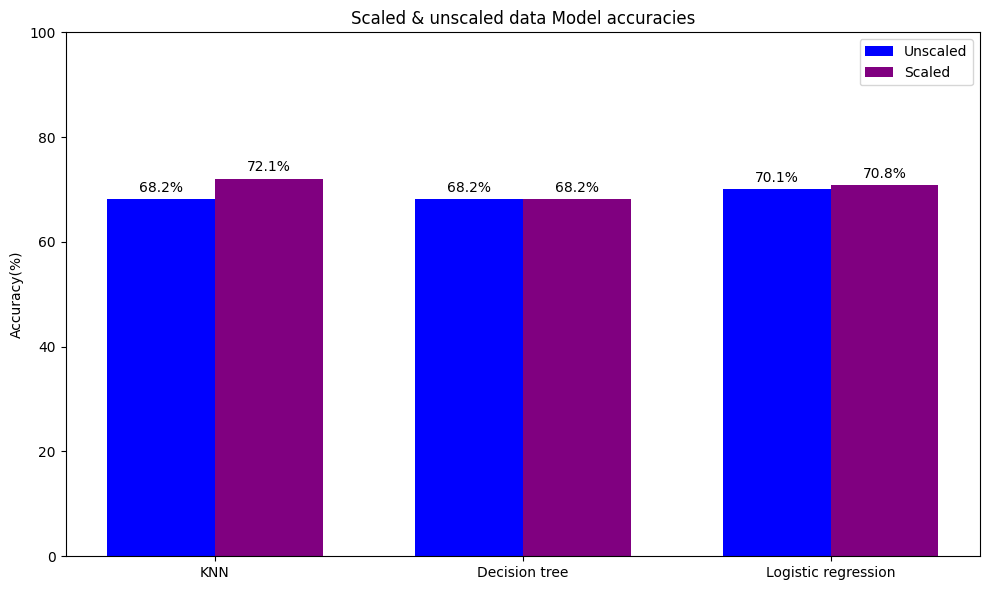


Classifications report for best performing (KNN) model:

              precision    recall  f1-score   support

Not Diabetic       0.79      0.78      0.78       100
    Diabetic       0.60      0.61      0.61        54

    accuracy                           0.72       154
   macro avg       0.69      0.70      0.69       154
weighted avg       0.72      0.72      0.72       154



In [28]:
models=["KNN","Decision tree","Logistic regression"]

unscaled_vals=[accuracy*100 for accuracy in unscaled_accuracies.values()]
scaled_vals=[accuracy*100 for accuracy in scaled_accuracies.values()]

x=np.arange(len(models))
width=0.35

fig,ax=plt.subplots(figsize=(10, 6))

rects1=ax.bar(x-width/2,unscaled_vals,width,label="Unscaled",color="blue")
rects2=ax.bar(x+width/2,scaled_vals,width,label="Scaled",color="purple")

ax.set_ylabel("Accuracy(%)")
ax.set_title("Scaled & unscaled data Model accuracies")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0,100)
ax.legend()

ax.bar_label(rects1,fmt="%.1f%%",padding=3)
ax.bar_label(rects2,fmt="%.1f%%",padding=3)

plt.tight_layout()
plt.show()
new_line()

best=pipelines["KNN"]
Y_pred=best.predict(X_test)
print("Classifications report for best performing (KNN) model:\n")
print(classification_report(Y_test,Y_pred,target_names=["Not Diabetic","Diabetic"]))

#Task 6

Q1: Which model was most accurate on the test set, and by how much?

Ans: KNN model was the most accurate on scaled data at 72.1% (3.9% better than Decision tree & 1.3% better than Logistic regression). And as for unscaled data, Logistic regression was the most accurate with 70.1% compared to 68.2% on the other two

Q2: The models scored close to 100% on Iris. Why are they much less accurate here?

Ans: As the flower's features are distinct from one another, but in the case of detecting diabetes, some features may be similar for two people even if one person has Diabetes and on does not. Thus, these sorts of feature overlaps make the model less accurate

Q3: 65% of patients are not diabetic. What accuracy would a model get by always predicting 'not diabetic'? Are your models much better than that?

Ans: That model would get 65% accuracy, whereas as mine one is more accurate at 72.1%. Thus, my model is slightly better, but perhaps not ideal

Q4: Change n_neighbors to 5, 9 and 15. How does the accuracy of your scaled KNN pipeline change?

In [29]:
for _ in [5,9,15]:
    pipeline=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=_))
    pipeline.fit(X_train,Y_train)
    predicted_X_values=pipeline.predict(X_test)
    acc=accuracy_score(Y_test,predicted_X_values)
    print(f"{_} neighbors has Accuracy: {acc:.4f}")

5 neighbors has Accuracy: 0.7532
9 neighbors has Accuracy: 0.7403
15 neighbors has Accuracy: 0.7403


For 5 neighbors, the model accuracy increases to 0.75 which far higher than 0.72 and this indicates that 5 neighbors is more suitable. This decreases slightly for 9 & 12 neighbors, but it still ends up being more accurate than 3 neighbors

Q5: A doctor wants to use one model for screening. Which would you choose, and why?

Ans: Due to the medical context, rather the maximum accuracy, we would prefer highest recall for Diabetic patients

In [30]:
dec_tree=pipelines["Decision Tree"]
Y_pred=dec_tree.predict(X_test)
print("Classifications report for Decision Tree model:\n")
print(classification_report(Y_test,Y_pred,target_names=["Not Diabetic","Diabetic"]))

log_reg=pipelines["Logistic Regression"]
Y_pred=log_reg.predict(X_test)
print("Classifications report for Logistic regression model:\n")
print(classification_report(Y_test,Y_pred,target_names=["Not Diabetic","Diabetic"]))

Classifications report for Decision Tree model:

              precision    recall  f1-score   support

Not Diabetic       0.74      0.79      0.76       100
    Diabetic       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67      0.68      0.68       154

Classifications report for Logistic regression model:

              precision    recall  f1-score   support

Not Diabetic       0.75      0.82      0.78       100
    Diabetic       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



When we compare these reports for the KNN model printed above, we can see that the KNN model has the highest recall for Diabetic patients (which is 0.61 as compared to 0.48 for Decision tree & 0.5 for Logistic regression). Hence, the scaled data KNN model is the most recommended choice

Q6: Re-run your three models on the original data without cleaning. Did handling the missing values change the accuracies? Suggest a reason.

Ans: In order to answer that, we can re-run our above code, but this type ommitting the data cleaning step

In [31]:
uncleaned_data=pd.read_csv("/content/diabetes.csv")

X_uncleaned=uncleaned_data[["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age"]]
Y_uncleaned=uncleaned_data["Outcome"]

X_uncleaned_training,X_uncleaned_testing,Y_uncleaned_training,Y_uncleaned_testing=train_test_split(X_uncleaned,Y_uncleaned,test_size=0.2,random_state=42,stratify=Y_uncleaned)

uncleaned_scaled_accuracies={}
for model_name,pipe in pipelines.items():
    pipe.fit(X_uncleaned_training,Y_uncleaned_training)
    acc_score=accuracy_score(Y_uncleaned_testing,pipe.predict(X_uncleaned_testing))
    uncleaned_scaled_accuracies[model_name]=acc_score

for unclean_model,uncleaned_model_accuracy in uncleaned_scaled_accuracies.items():
    print(f"{unclean_model} model on uncleaned & scaled data has accuracy {uncleaned_model_accuracy:.4f}")

new_line()
print(original_comparison_table)

KNN model on uncleaned & scaled data has accuracy 0.6948
Decision Tree model on uncleaned & scaled data has accuracy 0.7208
Logistic Regression model on uncleaned & scaled data has accuracy 0.7143

               Unscaled accuracy  Scaled accuracy
KNN                     0.681818         0.720779
Dec. tree               0.681818         0.681818
Logistic reg.           0.701299         0.707792


Comparing model accuracies for scaled data shows that for KNN model, accuracy drops when using uncleaned data from 72 to 69. This is due to the changed physical distances between uncleaned (zeros) points